In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torch import Tensor
from torchvision import transforms
import h5py

import matplotlib.pyplot as plt
import matplotlib.animation as animation

from IPython.display import HTML

import gc
import math
import random

# for deleting old best models
import os
import glob


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device is {device}")

Device is cuda


In [2]:
data_resolution = "224x224"
# from data resolution
num_input_params = 224 * 224
data_location = "../datasets/DDD-20-single-recording/out_files/recording_bin50msAPS.hdf5"
use_aps = True
use_stated = True
normalisation_precision = np.float16
# for models
save_path = "./models/"
batch_size = 60

In [3]:
with h5py.File(data_location, "r") as f:
    # headers = pd.DataFrame(np.array(h5py.File(data_location)))
    # print(f"The headers accessible are as such:\n{headers}")
    dvs_frame = np.array(f[f"dvs_frame_{data_resolution}"])
    speeds = np.array(f["vehicle_speed"])
    train_idxs = np.array(f["train_idxs"])
    test_idxs = np.array(f["test_idxs"])
    steering_angles = np.array(f["steering_wheel_angle"])
    if use_aps:
        aps_frame = np.array(f["aps_frame"])

In [4]:
# Function to generate predictions in batches
def generate_predictions(model, data_X, data_y, batch_size, device, transform):
    model.eval()
    predictions = []
    with torch.no_grad():
        for i in range(0, len(data_X), batch_size):
            batch_X = data_X[i:i+batch_size]
            batch_y = data_y[i:i+batch_size]
            transformed_batch_X = torch.stack([transform(img) for img in batch_X])
            batch_X_tensor = transformed_batch_X.to(device)
            batch_y_tensor = Tensor(batch_y).to(device)
            outputs = model(batch_X_tensor)
            predictions.extend(outputs.detach().cpu().numpy())
            del batch_X_tensor, batch_y_tensor, outputs
            torch.cuda.empty_cache()
            gc.collect()
    return predictions


In [5]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride = 1, downsample = None):
        super(ResidualBlock, self).__init__()
        self.conv1 = nn.Sequential(
                        nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                        nn.BatchNorm2d(out_channels),
                        nn.ReLU())
        self.conv2 = nn.Sequential(
                        nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                        nn.BatchNorm2d(out_channels))
        self.downsample = downsample
        self.relu = nn.ReLU()
        self.out_channels = out_channels

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.conv2(out)
        if self.downsample:
            residual = self.downsample(x)
        out += residual
        out = self.relu(out)
        return out

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.conv2(out)
        if self.downsample:
            residual = self.downsample(x)
        out += residual
        out = self.relu(out)
        return out

class ResNet(nn.Module):
    def __init__(self, block, layers, num_channels, num_classes = 1):
        super(ResNet, self).__init__()
        self.inplanes = 64
        self.conv1 = nn.Sequential(
                        nn.Conv2d(num_channels, 64, kernel_size = 7, stride = 2, padding = 3),
                        nn.BatchNorm2d(64),
                        nn.ReLU())
        self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
        self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
        self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
        self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
        self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
        self.avgpool = nn.AvgPool2d(7, stride=1)
        self.lstm = nn.LSTM(input_size=512, hidden_size=128, num_layers=1)
        self.fc = nn.Linear(128, num_classes)
        self._init_weights()
    
    # initialise as per the DDD20 Paper.
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
                nin = m.in_channels if hasattr(m, 'in_channels') else m.in_features
                m.weight.data.normal_(0, math.sqrt(2.0 / nin))
                if m.bias is not None:
                    m.bias.data.zero_()  

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes:

            downsample = nn.Sequential(
                nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                nn.BatchNorm2d(planes),
            )
        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample))
        self.inplanes = planes
        for i in range(1, blocks):
            layers.append(block(self.inplanes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        # rint(f"Conv1 shape is {x.shape}")
        x = self.maxpool(x)
        x = self.layer0(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        # print(f"shape of x after avgpool is {x.shape}")
        # x = x.view(x.size(0), -1)
        x = x.squeeze(-1)
        x = x.permute(0, 2, 1)
        '''
        Sequence length is the "batch size" as is used everywhere else.
        For each "batch", we must get the output of the LSTM for that batch.
        We will then feed those outputs as the respective outputs of the batches to the fc layer.
        '''
        lstm_out, _ = self.lstm(x)
        # output should be of size (sequence_size, batch_size, 512)
        # print(f"shape of lstm_out is {lstm_out.shape}")
        x = lstm_out.squeeze(1)
        x = self.fc(x)

        return x.squeeze(1)

In [6]:
class ResNetStated(nn.Module):
    def __init__(self, block, layers, num_channels, num_classes=1):
        super(ResNetStated, self).__init__()
        self.inplanes = 64
        self.conv1 = nn.Sequential(
            nn.Conv2d(num_channels, 64, kernel_size=7, stride=2, padding=3),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer0 = self._make_layer(block, 64, layers[0], stride=1)
        self.layer1 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer2 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer3 = self._make_layer(block, 512, layers[3], stride=2)
        self.avgpool = nn.AvgPool2d(7, stride=1)
        self.lstm = nn.LSTM(input_size=512, hidden_size=128, num_layers=1)
        self.fc = nn.Linear(128, num_classes)
        self._init_weights()
        self.hidden = None

    # Initialize weights as per the DDD20 Paper.
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
                nin = m.in_channels if hasattr(m, 'in_channels') else m.in_features
                m.weight.data.normal_(0, math.sqrt(2.0 / nin))
                if m.bias is not None:
                    m.bias.data.zero_()

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes:
            downsample = nn.Sequential(
                nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                nn.BatchNorm2d(planes),
            )
        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample))
        self.inplanes = planes
        for _ in range(1, blocks):
            layers.append(block(self.inplanes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.maxpool(x)
        x = self.layer0(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)

        # Detach hidden state to prevent backpropagating through the entire history
        if self.hidden is not None:
            self.hidden = tuple([h.detach() for h in self.hidden])

        x, self.hidden = self.lstm(x.unsqueeze(0), self.hidden)
        x = self.fc(x.squeeze(0))

        return x.squeeze(1)

In [7]:
dvs_min, dvs_max = 0, 255.0
aps_min, aps_max = 0, 255.0
inv_dvs_max = 1 / dvs_max
inv_aps_max = 1 / aps_max


print(f"DVS frames had a min of {dvs_min}, max of {dvs_max} and an average of {np.average(dvs_frame)}.")
# normalise in batches to stop kernel crashing due to memory
normalisation_batch_size = 1000
new_dvs_frame = np.empty_like(dvs_frame, dtype=normalisation_precision)
for i in range(0, len(dvs_frame), normalisation_batch_size):
    new_dvs_frame[i:i+normalisation_batch_size] = dvs_frame[i:i+normalisation_batch_size] * inv_dvs_max # this is shorthand for (batch - dvs_min) / (dvs_max - dvs_min) as dvs_min is 0

dvs_frame = new_dvs_frame
print(f"After normalisation, DVS has a min of {dvs_frame.min()}, max of {dvs_frame.max()} and an average of {np.average(dvs_frame)}.")

if use_aps:
    print(f"APS frames had a min of {aps_min}, max of {aps_max} and an average of {np.average(aps_frame)}.")
    # transform aps frame to correct 224 x 224 size
    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize((224, 224)),
        ])
    
    new_aps_frame = np.empty((aps_frame.shape[0], 224, 224), dtype=normalisation_precision)
    for i in range(0, len(aps_frame), normalisation_batch_size):
        for j in range(min(normalisation_batch_size, len(aps_frame) - i)):
            new_aps_frame[i + j] = transform(aps_frame[i + j])
        new_aps_frame[i:i+normalisation_batch_size] = new_aps_frame[i:i+normalisation_batch_size] * inv_aps_max # this is shorthand for (batch - aps_min) / (aps_max - aps_min) as aps_min is 0
    
    aps_frame = new_aps_frame
    print(f"After normalisation, APS has a min of {aps_frame.min()}, max of {aps_frame.max()} and an average of {np.average(aps_frame)}.")

DVS frames had a min of 0, max of 255.0 and an average of 81.51208719088106.


/home/oltans/virtual_environments/snn/lib/python3.12/site-packages/numpy/lib/function_base.py:522: RuntimeWarning: overflow encountered in cast
  scl = avg_as_array.dtype.type(a.size/avg_as_array.size)


After normalisation, DVS has a min of 0.0, max of 1.0 and an average of 0.319580078125.
APS frames had a min of 0, max of 255.0 and an average of 125.41317191131171.
After normalisation, APS has a min of 0.0, max of 1.0 and an average of 0.49169921875.


In [8]:
if use_aps:
    # 3 to have it be B x H x W x C
    combined_frames = np.stack((dvs_frame, aps_frame), axis=3)
    print(f"Combined frames shape is {combined_frames.shape}.")
    del dvs_frame, aps_frame
    gc.collect()
else:
    combined_frames = np.expand_dims(dvs_frame, axis=3)
    print(f"Combined frames shape is {combined_frames.shape}.")
    del dvs_frame
    gc.collect()

train_frames = combined_frames[train_idxs]
test_frames = combined_frames[test_idxs]
train_angles = steering_angles[train_idxs]
test_angles = steering_angles[test_idxs]
train_speeds = speeds[train_idxs]
#Rename to fit convention
train_X, train_y = train_frames, train_angles
test_X, test_y = test_frames, test_angles

Combined frames shape is (40960, 224, 224, 2).


In [9]:
if use_stated:
    if use_aps:
        model = ResNetStated(ResidualBlock, [3, 4, 6, 3], num_channels=2).to(device)
    else:
        model = ResNetStated(ResidualBlock, [3, 4, 6, 3], num_channels=1).to(device)
else:
    if use_aps:
        model = ResNet(ResidualBlock, [3, 4, 6, 3], num_channels=2).to(device)
    else:
        model = ResNet(ResidualBlock, [3, 4, 6, 3], num_channels=1).to(device)


RuntimeError: Expected hidden[0] size (1, 32, 128), got [1, 60, 128]

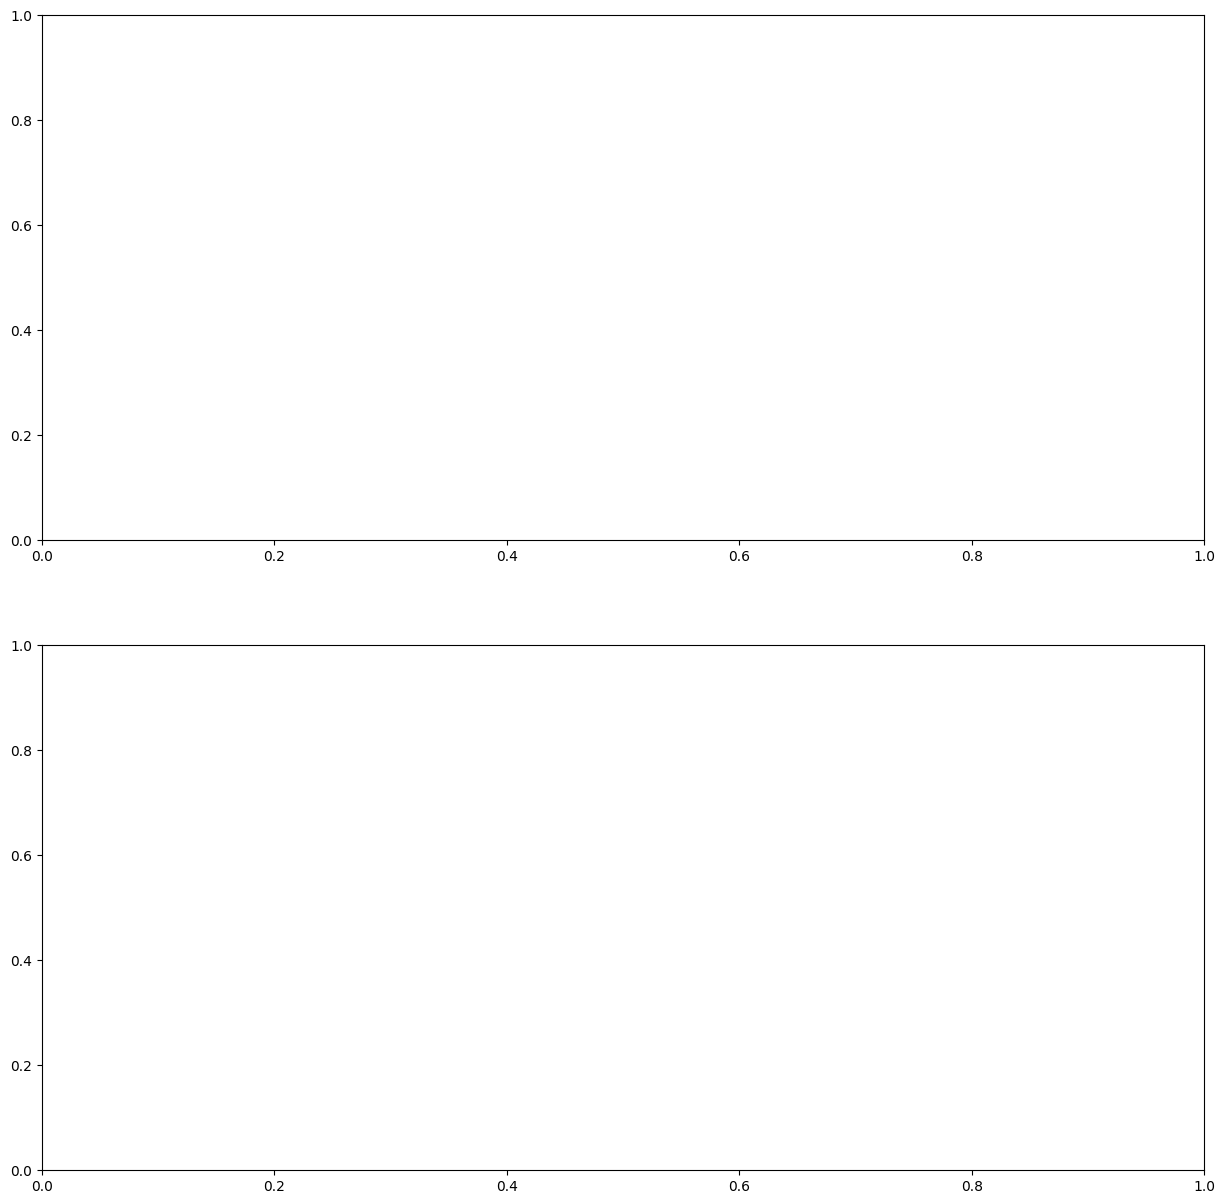

In [10]:
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.float())
])

model_files = [f for f in os.listdir(save_path) if f.endswith('.pth')]

# Add the best model to the list of models to plot
model_files.append(os.listdir(f"{save_path}/best")[0])

fig, axes = plt.subplots(2, 1, figsize=(15, 15))
train_ax, test_ax = axes

for model_file in model_files:
    epoch = model_file.split('_')[0]  # Extract "e99" from "e99_L 3.91.pth"
    model_dict = (torch.load(f"{save_path}/{model_file}", weights_only=True, map_location=device))
    model.load_state_dict(model_dict["model_state_dict"])
    model.to(device)
    
    train_predictions = generate_predictions(model, train_X, train_y, batch_size=batch_size, device=device, transform=transform)
    test_predictions = generate_predictions(model, test_X, test_y, batch_size=batch_size, device=device, transform=transform)
    
    train_ax.plot(train_predictions, label=epoch)
    test_ax.plot(test_predictions, label=epoch)

train_ax.plot(train_y, label='Ground Truth')
train_ax.set_xlabel('Sample')
train_ax.set_ylabel('Training Prediction')
train_ax.legend()

test_ax.plot(test_y, label='Ground Truth')
test_ax.set_xlabel('Sample')
test_ax.set_ylabel('Test Prediction')
test_ax.legend()

plt.show()